# 🔍 Détection d'Anomalies Réseau OLT/ONU
## Architecture à 3 rôles complémentaires

| Rôle | Algorithme | Type d'anomalie détectée | Features |
|---|---|---|---|
| 1️⃣ | **Z-Score** | Anomalie **univariée** — une seule mesure physique anormale | 4 continues |
| 2️⃣ | **Isolation Forest** | Anomalie **multivariée** — combinaison anormale de mesures | 4 continues |
| 3️⃣ | **Règles logiques** | Anomalie **logique** — incohérence d'état réseau | 3 binaires |

```


### Pourquoi cette séparation est scientifiquement correcte ?
Le Z-Score repose sur z = (x - μ) / σ. Pour être valide, σ doit être **représentatif**.
Avec F_SUSP (99% de 0) : σ = 0.03 → z = 33 quand =1 → absurde mathématiquement.
Les binaires sont donc traités par leur propre logique, sans normalisation.

## 1. 📦 Imports & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve
)
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.facecolor'] = '#F8F9FA'
plt.rcParams['axes.facecolor']   = '#F8F9FA'
plt.rcParams['axes.grid']        = True
plt.rcParams['grid.color']       = '#DEE2E6'
plt.rcParams['grid.alpha']       = 0.5

C_NORMAL  = '#4A90D9'   # bleu  — points normaux
C_ANOMALY = '#E74C3C'   # rouge — anomalies
C_ZSCORE  = '#F39C12'   # orange — Z-Score
C_IF      = '#2ECC71'   # vert  — Isolation Forest
C_BIN     = '#9B59B6'   # violet — règles binaires
C_FINAL   = '#E67E22'   # orange foncé — fusion
C_DARK    = '#2C3E50'

## 2. 📂 Chargement & Exploration

In [2]:
df = pd.read_excel('dataset_ml.xlsx')
print(f'Shape : {df.shape}')
print(f"Anomalies : {df['Anomalie'].sum()} ({df['Anomalie'].mean()*100:.2f}%)")
df.head()

Shape : (6692, 19)
Anomalies : 646 (9.65%)


,ID_LIGNE,ID_CARTE_OLT,NO_PORT,ONU_ID,F_SUSP,ADMIN_STATUS,OPER_STATUS,OLT_POWER_TX,OLT_RX_ONT_POWER,ONU_POWER_TX,ONU_POWER_RX,DESGOUV,Etat_OLT_TX,Etat_OLT_RX,Etat_ONU_TX,Etat_ONU_RX,Anomalie_technique,Anomalie_admin,Anomalie
0,80297937,63,1,60,0,1,1,3.4,-20.3,2.364,-19.43,SOUSSE,0,0,0,0,0,0,0
1,80298937,63,1,60,0,1,1,3.4,-20.3,2.364,-19.43,SOUSSE,0,0,0,0,0,0,0
2,80387937,63,1,60,0,1,1,3.4,-20.3,2.364,-19.43,SOUSSE,0,0,0,0,0,0,0
3,80397937,63,1,60,0,1,1,3.4,-20.3,2.364,-19.43,SOUSSE,0,0,0,0,0,0,0
4,80927937,63,1,60,0,1,1,3.4,-20.3,2.364,-19.43,SOUSSE,0,0,0,0,0,0,0


In [3]:
# Pourquoi on ne peut PAS mettre les binaires dans StandardScaler
print('=== Démonstration du problème des binaires dans Z-Score ===')
for col in ['F_SUSP', 'ADMIN_STATUS', 'OPER_STATUS']:
    mean_ = df[col].mean()
    std_  = df[col].std()
    z_si1 = (1 - mean_) / std_ if std_ > 0 else float('inf')
    print(f'  {col}: mean={mean_:.3f}  std={std_:.4f}  '
          f'→ Z-Score quand =1 : {z_si1:.1f}  ❌ (devrait être ~2-3 max)')
print()
print('→ Ces Z-Scores de 30+ écraseraient les mesures physiques (Z~2-3).')
print('→ Solution : traiter les binaires SÉPARÉMENT par règles logiques.')

=== Démonstration du problème des binaires dans Z-Score ===
  F_SUSP: mean=0.001  std=0.0299  → Z-Score quand =1 : 33.4  ❌ (devrait être ~2-3 max)
  ADMIN_STATUS: mean=0.982  std=0.1322  → Z-Score quand =1 : 0.1  ❌ (devrait être ~2-3 max)
  OPER_STATUS: mean=0.949  std=0.2196  → Z-Score quand =1 : 0.2  ❌ (devrait être ~2-3 max)

→ Ces Z-Scores de 30+ écraseraient les mesures physiques (Z~2-3).
→ Solution : traiter les binaires SÉPARÉMENT par règles logiques.


## 3. 🛠️ Feature Engineering — Incohérences d'État

On crée 3 colonnes binaires, chacune représentant une incohérence logique **précise et métier** :

| Feature | Condition | Signification métier |
|---|---|---|
| `inc_susp_admin` | `F_SUSP=1` ET `ADMIN_STATUS=1` | Ligne suspendue mais port encore activé |
| `inc_admin_oper` | `ADMIN_STATUS=0` ET `OPER_STATUS=1` | Port désactivé mais encore Online |
| `inc_susp_oper` | `F_SUSP=1` ET `OPER_STATUS=1` | Ligne suspendue mais encore Online |

> Ces colonnes ont une **Precision = 100%** : quand elles valent 1, c'est toujours une vraie anomalie.

In [4]:
df['inc_susp_admin'] = ((df['F_SUSP']==1) & (df['ADMIN_STATUS']==1)).astype(int)
df['inc_admin_oper'] = ((df['ADMIN_STATUS']==0) & (df['OPER_STATUS']==1)).astype(int)
df['inc_susp_oper']  = ((df['F_SUSP']==1) & (df['OPER_STATUS']==1)).astype(int)

feat_bin = ['inc_susp_admin', 'inc_admin_oper', 'inc_susp_oper']

print('--- Validation des incohérences ---')
for col in feat_bin:
    n1   = df[col].sum()
    prec = df[df[col]==1]['Anomalie'].mean() if n1 > 0 else 0
    std  = df[col].std()
    print(f'  {col}: {n1} cas | Precision={prec*100:.0f}% | std={std:.4f} '
          f'(trop petit pour Z-Score → règle logique directe)')

--- Validation des incohérences ---
  inc_susp_admin: 6 cas | Precision=100% | std=0.0299 (trop petit pour Z-Score → règle logique directe)
  inc_admin_oper: 23 cas | Precision=100% | std=0.0585 (trop petit pour Z-Score → règle logique directe)
  inc_susp_oper: 6 cas | Precision=100% | std=0.0299 (trop petit pour Z-Score → règle logique directe)


## 4. ⚙️ Préparation — StandardScaler sur continues uniquement

Le StandardScaler est appliqué **uniquement** sur les 4 features physiques continues.
Les features binaires restent intactes et seront utilisées par des règles logiques directes.

In [5]:
feat_cont     = ['OLT_POWER_TX', 'OLT_RX_ONT_POWER', 'ONU_POWER_TX', 'ONU_POWER_RX']
y_true        = df['Anomalie'].values
contamination = y_true.mean()

scaler        = StandardScaler()
X_scaled      = scaler.fit_transform(df[feat_cont])

y_binary = (df[feat_bin].sum(axis=1) >= 1).astype(int)

print(f'Features continues scalées : {feat_cont}')
print(f'Features binaires (règles) : {feat_bin}')
print(f'Contamination              : {contamination:.4f}')
print(f'Anomalies binaires         : {y_binary.sum()}')

Features continues scalées : ['OLT_POWER_TX', 'OLT_RX_ONT_POWER', 'ONU_POWER_TX', 'ONU_POWER_RX']
Features binaires (règles) : ['inc_susp_admin', 'inc_admin_oper', 'inc_susp_oper']
Contamination              : 0.0965
Anomalies binaires         : 29


## 5. 📐 Rôle 1 — Z-Score : Anomalies Univariées

### Principe
Le Z-Score évalue **chaque feature indépendamment** :
$$z_i = \frac{x_i - \mu_i}{\sigma_i}$$

Une ligne est anomalie si **au moins une** de ses 4 mesures est anormale :
$$z_{max} = \max(|z_{OLT\_TX}|, |z_{OLT\_RX}|, |z_{ONU\_TX}|, |z_{ONU\_RX}|) > 2.0$$

### Ce que Z-Score détecte
✅ `OLT_POWER_TX = 0.5` alors que la moyenne est 4.3 → anomalie univariée claire

❌ `OLT_POWER_TX = 4.0` ET `ONU_POWER_RX = -35` simultanément → Z-Score peut rater
car chaque valeur prise seule semble acceptable

In [6]:
THRESHOLD_ZSCORE = 2.0

z_scores     = np.abs(X_scaled)           
z_max        = z_scores.max(axis=1)       
z_which_feat = z_scores.argmax(axis=1)    
y_zscore     = (z_max > THRESHOLD_ZSCORE).astype(int)

print(f'Anomalies détectées par Z-Score : {y_zscore.sum()}')


detected_feats = pd.Series(z_which_feat[y_zscore==1]).map(
    dict(enumerate(feat_cont))
).value_counts()
print('\n--- Feature déclenchante (parmi les anomalies détectées) ---')
print(detected_feats)

print('\n=== Rapport Z-Score (univarié) ===')
print(classification_report(y_true, y_zscore, target_names=['Normal','Anomalie']))
print(f'AUC-ROC : {roc_auc_score(y_true, z_max):.4f}')

Anomalies détectées par Z-Score : 693

--- Feature déclenchante (parmi les anomalies détectées) ---
OLT_RX_ONT_POWER    297
ONU_POWER_RX        231
ONU_POWER_TX        159
OLT_POWER_TX          6
Name: count, dtype: int64

=== Rapport Z-Score (univarié) ===
              precision    recall  f1-score   support

      Normal       0.99      0.98      0.99      6046
    Anomalie       0.85      0.91      0.88       646

    accuracy                           0.98      6692
   macro avg       0.92      0.95      0.93      6692
weighted avg       0.98      0.98      0.98      6692

AUC-ROC : 0.9724


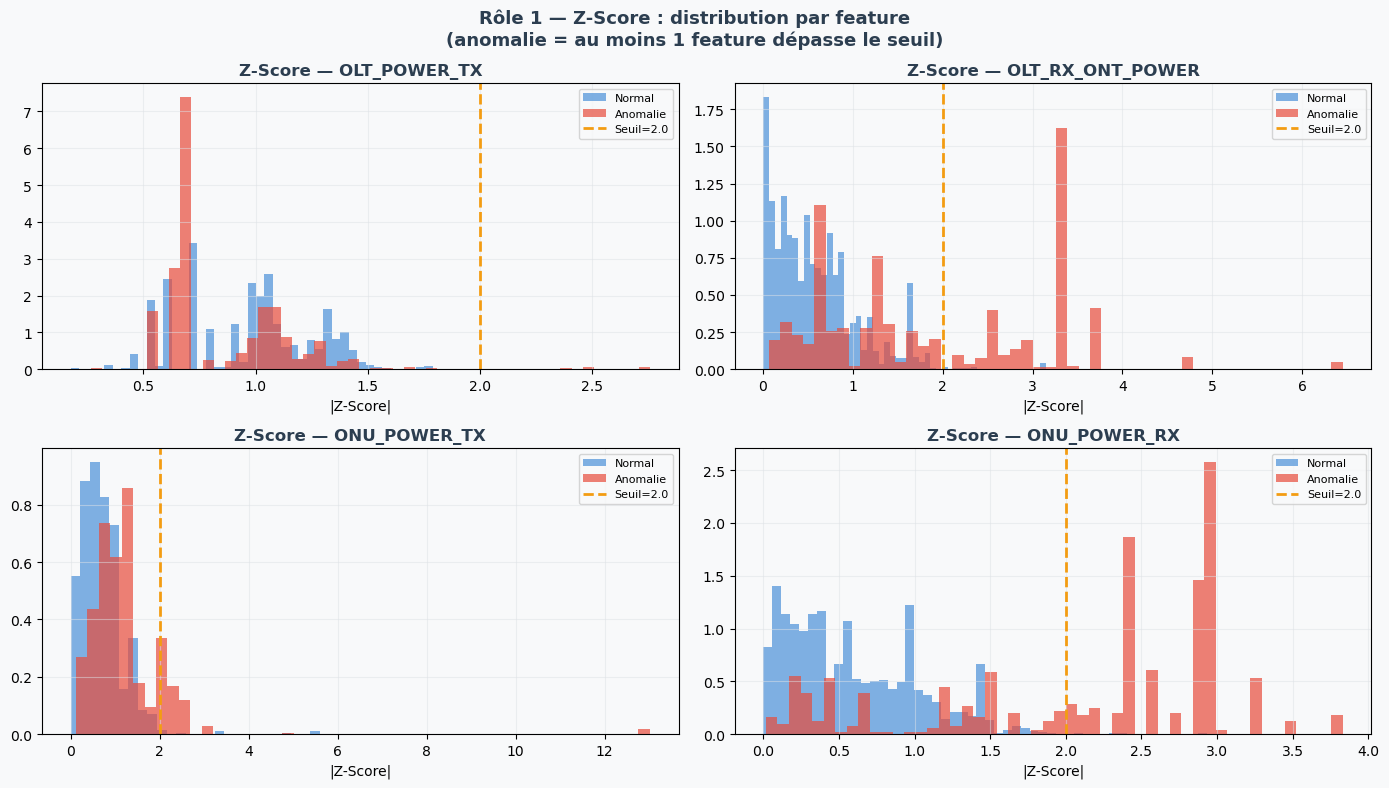

In [7]:
# Distribution des Z-Scores par feature
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, i, feat in zip(axes.flatten(), range(4), feat_cont):
    for val, c, lbl in [(0, C_NORMAL,'Normal'),(1, C_ANOMALY,'Anomalie')]:
        mask = y_true == val
        ax.hist(z_scores[mask, i], bins=50, alpha=0.7,
                color=c, label=lbl, density=True)
    ax.axvline(THRESHOLD_ZSCORE, color=C_ZSCORE, lw=2, ls='--',
               label=f'Seuil={THRESHOLD_ZSCORE}')
    ax.set_title(f'Z-Score — {feat}', fontweight='bold', color=C_DARK)
    ax.set_xlabel('|Z-Score|'); ax.legend(fontsize=8)
plt.suptitle('Rôle 1 — Z-Score : distribution par feature\n'
             '(anomalie = au moins 1 feature dépasse le seuil)',
             fontsize=13, fontweight='bold', color=C_DARK)
plt.tight_layout(); plt.show()

## 6. 🌲 Rôle 2 — Isolation Forest : Anomalies Multivariées

### Principe
Isolation Forest construit des arbres aléatoires et mesure combien de coupures
sont nécessaires pour isoler un point. Les anomalies sont **isolées plus vite**.

### Ce que Isolation Forest détecte QUE Z-Score rate
Imaginons :
- `OLT_POWER_TX = 4.0` → Z-Score normal ✅
- `ONU_POWER_RX = -20` → Z-Score normal ✅
- Mais cette **combinaison** n'existe jamais ensemble dans les données normales
→ Isolation Forest détecte l'anomalie ✅ — Z-Score la rate ❌

### Complémentarité avec Z-Score
Les deux algorithmes ont des **zones de détection différentes** — c'est pourquoi on les utilise ensemble.

In [8]:
iso = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    random_state=42,
    max_samples='auto'
)
iso.fit(X_scaled)

y_if      = (iso.predict(X_scaled) == -1).astype(int)
if_scores = -iso.score_samples(X_scaled)  # score élevé = plus anormal

print(f'Anomalies détectées par Isolation Forest : {y_if.sum()}')

print('\n=== Rapport Isolation Forest (multivarié) ===')
print(classification_report(y_true, y_if, target_names=['Normal','Anomalie']))
print(f'AUC-ROC : {roc_auc_score(y_true, if_scores):.4f}')

Anomalies détectées par Isolation Forest : 645

=== Rapport Isolation Forest (multivarié) ===
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98      6046
    Anomalie       0.78      0.78      0.78       646

    accuracy                           0.96      6692
   macro avg       0.88      0.88      0.88      6692
weighted avg       0.96      0.96      0.96      6692

AUC-ROC : 0.9564


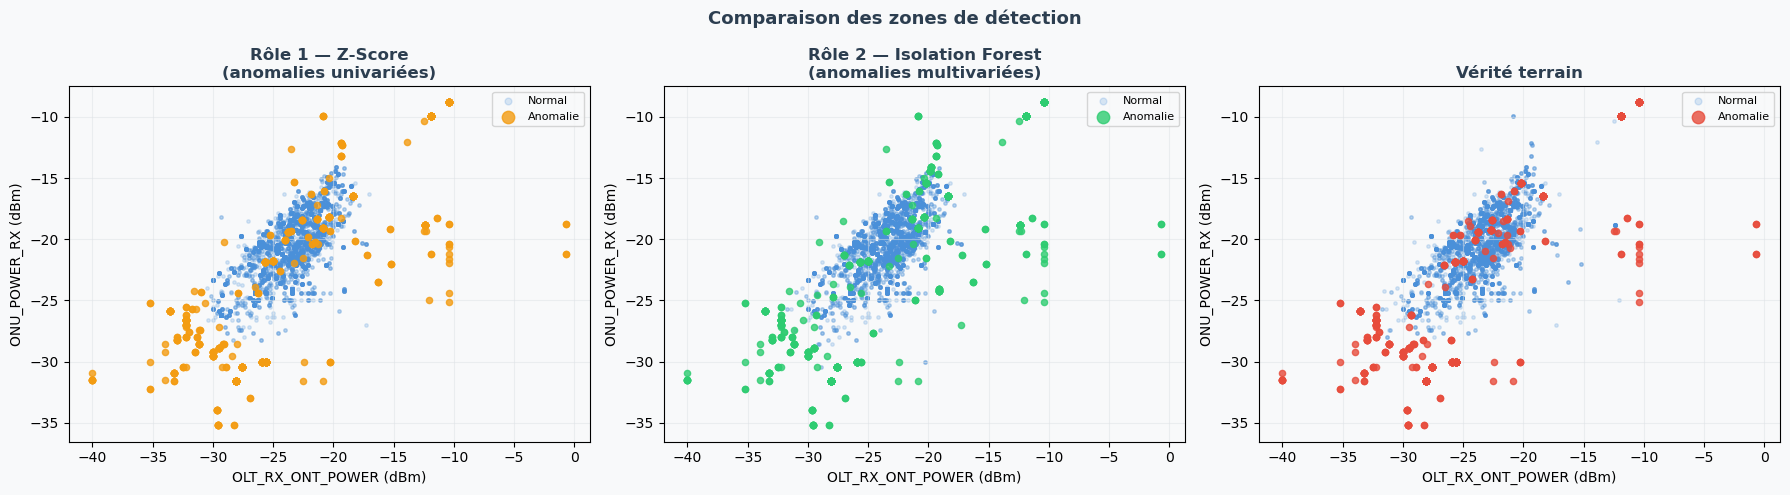

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pairs = [('OLT_RX_ONT_POWER', 'ONU_POWER_RX')]

configs = [
    (y_zscore, 'Rôle 1 — Z-Score\n(anomalies univariées)', C_ZSCORE),
    (y_if,     'Rôle 2 — Isolation Forest\n(anomalies multivariées)', C_IF),
    (y_true,   'Vérité terrain', C_ANOMALY),
]
for ax, (yp, title, col) in zip(axes, configs):
    ax.scatter(df['OLT_RX_ONT_POWER'][yp==0], df['ONU_POWER_RX'][yp==0],
               c=C_NORMAL, alpha=0.2, s=6, label='Normal')
    ax.scatter(df['OLT_RX_ONT_POWER'][yp==1], df['ONU_POWER_RX'][yp==1],
               c=col, alpha=0.8, s=20, label='Anomalie', zorder=5)
    ax.set_xlabel('OLT_RX_ONT_POWER (dBm)')
    ax.set_ylabel('ONU_POWER_RX (dBm)')
    ax.set_title(title, fontweight='bold', color=C_DARK)
    ax.legend(fontsize=8, markerscale=2)
plt.suptitle('Comparaison des zones de détection',
             fontsize=13, fontweight='bold', color=C_DARK)
plt.tight_layout(); plt.show()

## 7. 🔗 Rôle 3 — Règles Logiques : Anomalies d'État

### Principe
Les incohérences d'état ne sont **pas détectables** par des algorithmes statistiques
car elles concernent la **logique métier** du réseau, pas les valeurs numériques.

### Ce que les règles détectent QUE Z-Score et IF ratent
Une ligne avec `F_SUSP=1` et `ADMIN_STATUS=1` peut avoir des valeurs de puissance
**parfaitement normales** → Z-Score et IF ne voient rien → Règle logique détecte ✅

### Preuve de la complémentarité
28 anomalies sont détectées **uniquement** par les règles binaires — invisibles pour Z-Score et IF.

In [10]:
y_binary = (df[feat_bin].sum(axis=1) >= 1).astype(int)

print('=== Rapport — Règles logiques (anomalies d\'état) ===')
print(classification_report(y_true, y_binary, target_names=['Normal','Anomalie']))


only_bin = ((y_binary==1) & (y_zscore==0) & (y_if==0))
print(f'Anomalies détectées UNIQUEMENT par règles binaires : {only_bin.sum()}')
print('→ Ces cas ont des valeurs de puissance normales mais une incohérence logique.')
print(df.loc[only_bin, feat_cont + feat_bin].head(5).to_string())

=== Rapport — Règles logiques (anomalies d'état) ===
              precision    recall  f1-score   support

      Normal       0.91      1.00      0.95      6046
    Anomalie       1.00      0.04      0.09       646

    accuracy                           0.91      6692
   macro avg       0.95      0.52      0.52      6692
weighted avg       0.92      0.91      0.87      6692

Anomalies détectées UNIQUEMENT par règles binaires : 28
→ Ces cas ont des valeurs de puissance normales mais une incohérence logique.
      OLT_POWER_TX  OLT_RX_ONT_POWER  ONU_POWER_TX  ONU_POWER_RX  inc_susp_admin  inc_admin_oper  inc_susp_oper
229           5.64            -25.86         2.330       -19.660               1               0              1
489           3.60            -24.30         2.674       -23.280               1               0              1
512           5.85            -21.25         2.340       -16.900               1               0              1
1718          3.70            -29.30  

## 8. 🔀 Complémentarité des 3 Approches

La question : **'Pourquoi utiliser deux algorithmes ?'**

La réponse : parce qu'ils détectent des **types d'anomalies différents**.

In [11]:
only_z   = ((y_zscore==1) & (y_if==0)     & (y_binary==0)).sum()
only_if  = ((y_if==1)     & (y_zscore==0)  & (y_binary==0)).sum()
only_bin = ((y_binary==1) & (y_zscore==0)  & (y_if==0)).sum()
z_and_if = ((y_zscore==1) & (y_if==1)      & (y_binary==0)).sum()
all3     = ((y_zscore==1) & (y_if==1)      & (y_binary==1)).sum()

print('=== Complémentarité des 3 approches ===')
print(f'  Détectés par Z-Score SEULEMENT    : {only_z:3d}  → anomalies univariées pures')
print(f'  Détectés par IF SEULEMENT         : {only_if:3d}  → anomalies multivariées pures')
print(f'  Détectés par Règles SEULEMENT     : {only_bin:3d}  → anomalies logiques invisibles')
print(f'  Détectés par Z-Score ET IF        : {z_and_if:3d}  → anomalies fortes (les deux voient)')
print(f'  Détectés par les 3                : {all3:3d}  → anomalies très claires')
print()
print('→ Supprimer Z-Score = perdre', only_z, 'détections')
print('→ Supprimer IF      = perdre', only_if, 'détections')
print('→ Supprimer Règles  = perdre', only_bin, 'détections')

=== Complémentarité des 3 approches ===
  Détectés par Z-Score SEULEMENT    : 125  → anomalies univariées pures
  Détectés par IF SEULEMENT         :  77  → anomalies multivariées pures
  Détectés par Règles SEULEMENT     :  28  → anomalies logiques invisibles
  Détectés par Z-Score ET IF        : 567  → anomalies fortes (les deux voient)
  Détectés par les 3                :   1  → anomalies très claires

→ Supprimer Z-Score = perdre 125 détections
→ Supprimer IF      = perdre 77 détections
→ Supprimer Règles  = perdre 28 détections


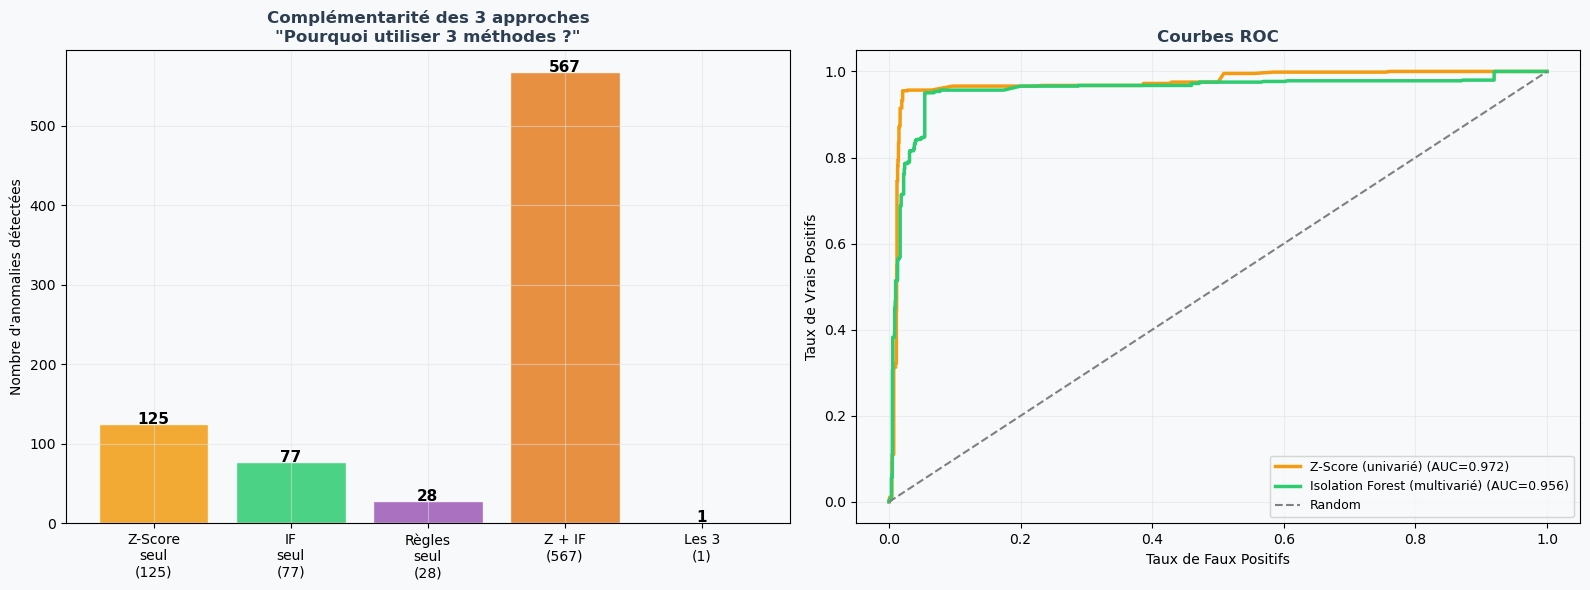

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Barres de complémentarité
ax = axes[0]
categories = [
    f'Z-Score\nseul\n({only_z})',
    f'IF\nseul\n({only_if})',
    f'Règles\nseul\n({only_bin})',
    f'Z + IF\n({z_and_if})',
    f'Les 3\n({all3})'
]
vals   = [only_z, only_if, only_bin, z_and_if, all3]
colors = [C_ZSCORE, C_IF, C_BIN, C_FINAL, C_ANOMALY]
bars = ax.bar(categories, vals, color=colors, alpha=0.85, edgecolor='white')
for bar, v in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            str(v), ha='center', fontweight='bold', fontsize=11)
ax.set_title('Complémentarité des 3 approches\n'
             '"Pourquoi utiliser 3 méthodes ?"',
             fontweight='bold', color=C_DARK)
ax.set_ylabel('Nombre d\'anomalies détectées')

# Courbes ROC
ax = axes[1]
for scores, name, col in [
        (z_max,    'Z-Score (univarié)',          C_ZSCORE),
        (if_scores,'Isolation Forest (multivarié)',C_IF)]:
    fpr, tpr, _ = roc_curve(y_true, scores)
    auc_val = roc_auc_score(y_true, scores)
    ax.plot(fpr, tpr, color=col, lw=2.5,
            label=f'{name} (AUC={auc_val:.3f})')
ax.plot([0,1],[0,1],'--',color='gray',lw=1.5,label='Random')
ax.set_xlabel('Taux de Faux Positifs')
ax.set_ylabel('Taux de Vrais Positifs')
ax.set_title('Courbes ROC', fontweight='bold', color=C_DARK)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 9. 🔗 Fusion OR — Résultat Final

Chaque approche couvre une zone de détection différente.
La fusion OR garantit qu'**aucun type d'anomalie n'est manqué**.

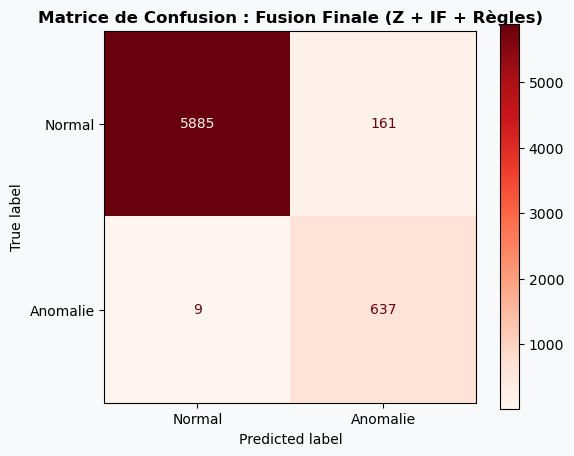

                             Precision Recall     F1    AUC
1️⃣ Z-Score (univarié)           0.853  0.915  0.883  0.972
2️⃣ Isolation Forest (multi)     0.777  0.776  0.776  0.956
3️⃣ Règles logiques                1.0  0.045  0.086      -
✅ Z-Score + Règles               0.859  0.958  0.906      -
✅ IF + Règles                    0.786  0.819  0.802      -


In [13]:
y_final_z  = ((y_zscore==1) | (y_binary==1)).astype(int)
y_final_if = ((y_if==1)     | (y_binary==1)).astype(int)
y_final    = ((y_zscore==1) | (y_if==1) | (y_binary==1)).astype(int)


# Matrice de confusion pour la fusion finale
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_final, 
    display_labels=['Normal', 'Anomalie'], 
    cmap='Reds',
    ax=ax
)
ax.set_title('Matrice de Confusion : Fusion Finale (Z + IF + Règles)', fontweight='bold')
plt.grid(False)
plt.show()

def get_metrics(y_true, y_pred, scores=None):
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    p = tp/(tp+fp) if (tp+fp)>0 else 0
    r = tp/(tp+fn) if (tp+fn)>0 else 0
    f = 2*p*r/(p+r) if (p+r)>0 else 0
    auc = round(roc_auc_score(y_true, scores),3) if scores is not None else '-'
    return {'Precision':round(p,3),'Recall':round(r,3),'F1':round(f,3),'AUC':auc}

summary = pd.DataFrame({
    '1️⃣ Z-Score (univarié)'       : get_metrics(y_true, y_zscore,    z_max),
    '2️⃣ Isolation Forest (multi)' : get_metrics(y_true, y_if,        if_scores),
    '3️⃣ Règles logiques'          : get_metrics(y_true, y_binary),
    '✅ Z-Score + Règles'          : get_metrics(y_true, y_final_z),
    '✅ IF + Règles'               : get_metrics(y_true, y_final_if),
}).T
print(summary.to_string())

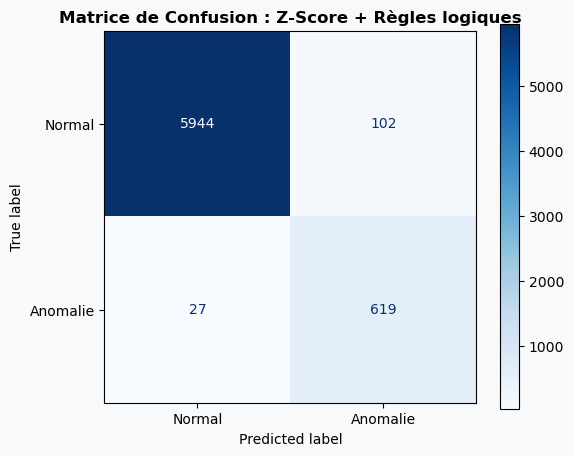

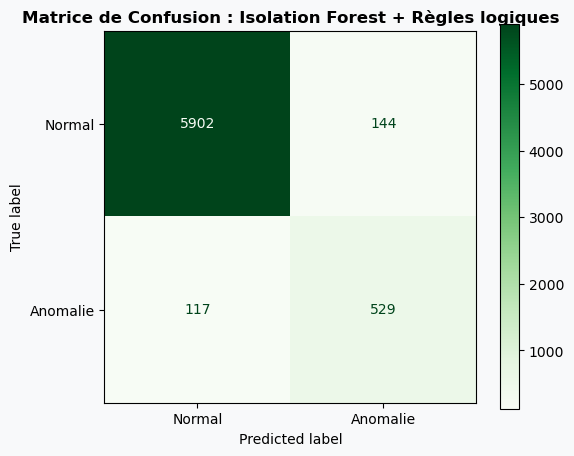

In [14]:
# === Matrice de confusion : Z-Score + Règles logiques ===
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_final_z,
    display_labels=['Normal', 'Anomalie'],
    cmap='Blues',
    ax=ax
)
ax.set_title('Matrice de Confusion : Z-Score + Règles logiques', fontweight='bold')
plt.grid(False)
plt.show()

# === Matrice de confusion : IF + Règles logiques ===
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_final_if,
    display_labels=['Normal', 'Anomalie'],
    cmap='Greens',
    ax=ax
)
ax.set_title('Matrice de Confusion : Isolation Forest + Règles logiques', fontweight='bold')
plt.grid(False)
plt.show()

## 10. 🔧 Tuning des Hyperparamètres

Meilleur seuil Z-Score : 2.0  (F1=0.9056)


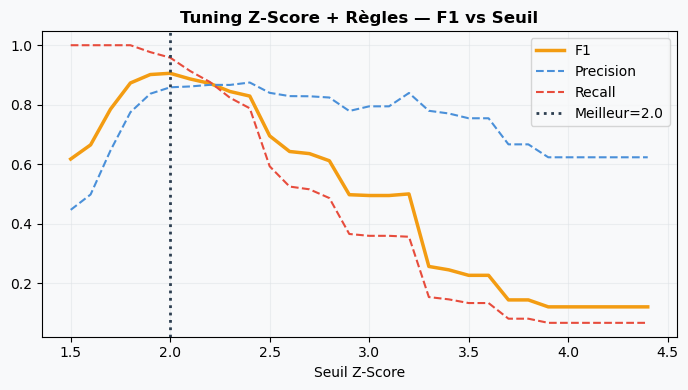

In [15]:
# Z-Score : F1 vs seuil (avec règles binaires)
thresholds = np.arange(1.5, 4.5, 0.1)
f1_z, prec_z, rec_z = [], [], []
for t in thresholds:
    yp = ((z_max > t) | (y_binary==1)).astype(int)
    tn2,fp2,fn2,tp2 = confusion_matrix(y_true, yp, labels=[0,1]).ravel()
    p = tp2/(tp2+fp2) if (tp2+fp2)>0 else 0
    r = tp2/(tp2+fn2) if (tp2+fn2)>0 else 0
    f1_z.append(2*p*r/(p+r) if (p+r)>0 else 0)
    prec_z.append(p); rec_z.append(r)
best_t = thresholds[np.argmax(f1_z)]
print(f'Meilleur seuil Z-Score : {best_t:.1f}  (F1={max(f1_z):.4f})')

plt.figure(figsize=(7,4))
plt.plot(thresholds, f1_z,   color=C_ZSCORE, lw=2.5, label='F1')
plt.plot(thresholds, prec_z, color=C_NORMAL,  lw=1.5, ls='--', label='Precision')
plt.plot(thresholds, rec_z,  color=C_ANOMALY, lw=1.5, ls='--', label='Recall')
plt.axvline(best_t, color=C_DARK, ls=':', lw=2, label=f'Meilleur={best_t:.1f}')
plt.xlabel('Seuil Z-Score')
plt.title('Tuning Z-Score + Règles — F1 vs Seuil', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

Meilleur n_estimators : 200  (F1=0.8021)


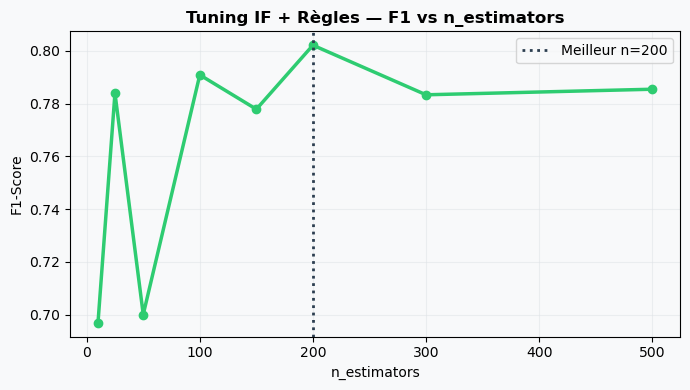

In [16]:
# Isolation Forest : F1 vs n_estimators (avec règles binaires)
est_vals, f1_if_vals = [10,25,50,100,150,200,300,500], []
for n in est_vals:
    iso_t = IsolationForest(n_estimators=n, contamination=contamination, random_state=42)
    iso_t.fit(X_scaled)
    yp = ((iso_t.predict(X_scaled)==-1) | (y_binary==1)).astype(int)
    tn2,fp2,fn2,tp2 = confusion_matrix(y_true, yp, labels=[0,1]).ravel()
    p = tp2/(tp2+fp2) if (tp2+fp2)>0 else 0
    r = tp2/(tp2+fn2) if (tp2+fn2)>0 else 0
    f1_if_vals.append(2*p*r/(p+r) if (p+r)>0 else 0)
best_n = est_vals[np.argmax(f1_if_vals)]
print(f'Meilleur n_estimators : {best_n}  (F1={max(f1_if_vals):.4f})')

plt.figure(figsize=(7,4))
plt.plot(est_vals, f1_if_vals, color=C_IF, lw=2.5, marker='o', ms=6)
plt.axvline(best_n, color=C_DARK, ls=':', lw=2, label=f'Meilleur n={best_n}')
plt.xlabel('n_estimators'); plt.ylabel('F1-Score')
plt.title('Tuning IF + Règles — F1 vs n_estimators', fontweight='bold')
plt.legend(); plt.tight_layout(); plt.show()

## 11. 🚀 Prédiction sur Nouvelles Données

La fonction applique automatiquement les 3 rôles et retourne un diagnostic complet.

In [17]:
def predict_anomaly_zscore_rules(new_data: pd.DataFrame) -> pd.DataFrame:
    """
    Détection d'anomalies : règles logiques + z-score univarié
    Colonnes requises :
        OLT_POWER_TX, OLT_RX_ONT_POWER, ONU_POWER_TX, ONU_POWER_RX,
        F_SUSP, ADMIN_STATUS, OPER_STATUS
    """
    result = new_data.copy()
    
    # ----------------------
    # Règles logiques
    # ----------------------
    result['inc_susp_admin']   = ((result['F_SUSP']==1) & (result['ADMIN_STATUS']==1)).astype(int)
    result['inc_admin_oper']   = ((result['ADMIN_STATUS']==0) & (result['OPER_STATUS']==1)).astype(int)
    result['inc_susp_oper']    = ((result['F_SUSP']==1) & (result['OPER_STATUS']==1)).astype(int)
    result['anomalie_logique'] = (result[feat_bin].sum(axis=1) >= 1).astype(int)
    
    # ----------------------
    # Z-score univarié (continuous features)
    # ----------------------
    X_new  = scaler.transform(result[feat_cont])
    z_new  = np.abs(X_new).max(axis=1)
    result['score_zscore']     = z_new.round(3)
    result['anomalie_univarie']= (z_new > THRESHOLD_ZSCORE).astype(int)
    
    # ----------------------
    # Fusion finale (OR logique)
    # ----------------------
    result['anomalie_finale'] = (
        (result['anomalie_univarie']==1) | (result['anomalie_logique']==1)
    ).astype(int)
    
    # ----------------------
    # Colonnes de sortie
    # ----------------------
    out = [
        'OLT_POWER_TX','OLT_RX_ONT_POWER','ONU_POWER_TX','ONU_POWER_RX',
        'anomalie_logique','score_zscore','anomalie_univarie','anomalie_finale'
    ]
    return result[out]

raw_cols = feat_cont + ['F_SUSP','ADMIN_STATUS','OPER_STATUS']
sample   = df[raw_cols].sample(8, random_state=42)
predict_anomaly_zscore_rules(sample)

,OLT_POWER_TX,OLT_RX_ONT_POWER,ONU_POWER_TX,ONU_POWER_RX,anomalie_logique,score_zscore,anomalie_univarie,anomalie_finale
247,3.10,-13.90,2.378,-12.042,0,2.699,1,1
5417,5.53,-27.64,2.290,-19.700,0,1.194,0,0
6085,5.49,-26.59,2.170,-20.650,0,1.057,0,0
1038,3.50,-22.20,2.674,-20.810,0,1.241,0,0
5700,5.78,-28.54,2.080,-24.310,0,1.449,0,0
1452,2.80,-26.50,2.302,-24.436,0,1.334,0,0
4674,3.40,-20.30,2.364,-19.430,0,0.886,0,0
2323,5.75,-33.60,2.280,-25.850,0,2.883,1,1


In [18]:
import pandas as pd

# Charger le dataset OLAP pour récupérer ID_LIGNE et DATE_MESURE
df_olap = pd.read_excel('dataset_olap_final_enriched.xlsx')[['ID_LIGNE', 'DATE_MESURE']]

# Fusionner avec les résultats ML
df_merged = df.merge(df_olap, on='ID_LIGNE', how='left')

print(f"Lignes après fusion : {len(df_merged)}")
print(f"DATE_MESURE récupérée : {df_merged['DATE_MESURE'].notna().sum()} lignes")

Lignes après fusion : 6700
DATE_MESURE récupérée : 6700 lignes


In [19]:
ids_dup_df = df[df['ID_LIGNE'].duplicated(keep=False)]
ids_dup_olap = df_olap[df_olap['ID_LIGNE'].duplicated(keep=False)]

In [20]:
print("df (ML) :", len(df))
print("df_olap :", len(df_olap))
print("ID_LIGNE uniques dans df :", df['ID_LIGNE'].nunique())

df (ML) : 6692
df_olap : 6692
ID_LIGNE uniques dans df : 6688


In [21]:
df_olap_unique = df_olap.drop_duplicates(subset='ID_LIGNE')

df_merged = df.merge(df_olap_unique, on='ID_LIGNE', how='left')

In [22]:
# PREDICTION_ANOMALIE avec DATE_MESURE récupérée depuis OLAP
PREDICTION_ANOMALIE = df_merged[['ID_LIGNE', 'DATE_MESURE']].copy()
PREDICTION_ANOMALIE.insert(0, 'ID_PREDICTION', range(1, len(df_merged) + 1))
PREDICTION_ANOMALIE['score_isolation_forest'] = (-iso.score_samples(X_scaled)).round(4)
PREDICTION_ANOMALIE['label_isolation_forest'] = y_if
PREDICTION_ANOMALIE['score_zscore']           = z_max.round(4)
PREDICTION_ANOMALIE['label_zscore']           = y_zscore
PREDICTION_ANOMALIE['label_binaire']          = y_binary
PREDICTION_ANOMALIE['anomalie_finale']        = y_final_z

PREDICTION_ANOMALIE.to_excel('PREDICTION_ANOMALIE.xlsx', index=False)
print(f"Exporté : {len(PREDICTION_ANOMALIE)} lignes | {PREDICTION_ANOMALIE['anomalie_finale'].sum()} anomalies")


Exporté : 6692 lignes | 721 anomalies


In [23]:
# LOG_INCIDENTS — uniquement les anomalies
mask = y_final_z == 1
LOG_INCIDENTS = df_merged[mask][[
    'ID_LIGNE', 'DATE_MESURE',
    'OLT_POWER_TX', 'OLT_RX_ONT_POWER', 'ONU_POWER_TX', 'ONU_POWER_RX',
    'F_SUSP', 'ADMIN_STATUS', 'OPER_STATUS'
]].copy()

LOG_INCIDENTS.insert(0, 'ID_INCIDENT', range(1, len(LOG_INCIDENTS) + 1))
LOG_INCIDENTS['score_zscore'] = z_max[mask].round(4)

def get_source(i):
    s = []
    if y_zscore[i] == 1: s.append('Z-SCORE')
    if y_binary[i] == 1: s.append('REGLE')
    return '+'.join(s)

LOG_INCIDENTS['SOURCE'] = [get_source(i) for i in df_merged[mask].index]

def get_severity(z):
    if z > 3.0: return 'CRITIQUE'
    if z > 2.0: return 'MODERE'
    return 'LOGIQUE'

LOG_INCIDENTS['SEVERITE'] = LOG_INCIDENTS['score_zscore'].apply(get_severity)
LOG_INCIDENTS['STATUT'] = 'DETECTE'

LOG_INCIDENTS.to_excel('LOG_INCIDENTS.xlsx', index=False)
print(f"Exporté : {len(LOG_INCIDENTS)} incidents")
print(LOG_INCIDENTS['SEVERITE'].value_counts())


Exporté : 721 incidents
SEVERITE
MODERE      429
CRITIQUE    264
LOGIQUE      28
Name: count, dtype: int64


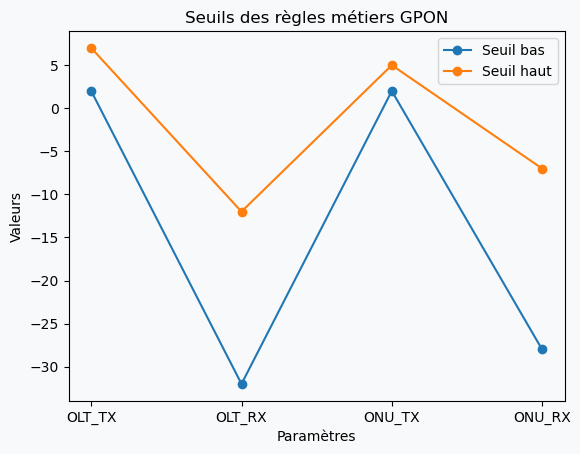

In [24]:
import matplotlib.pyplot as plt

params = ["OLT_TX", "OLT_RX", "ONU_TX", "ONU_RX"]
low = [2, -32, 2, -28]
high = [7, -12, 5, -7]

plt.figure()
plt.plot(params, low, marker='o', label='Seuil bas')
plt.plot(params, high, marker='o', label='Seuil haut')

plt.title("Seuils des règles métiers GPON")
plt.xlabel("Paramètres")
plt.ylabel("Valeurs")
plt.legend()
plt.grid()

plt.show()

In [25]:
import joblib
# Rebuild and save the .pkl files
joblib.dump(THRESHOLD_ZSCORE, 'models/zscore_threshold.pkl')
joblib.dump(scaler, 'models/scaler.pkl')
joblib.dump(iso, 'models/isolation_forest.pkl')
joblib.dump(y_final_z, 'models/y_final_z.pkl')
print("Fichiers .pkl sauvegardés avec succès.")

Fichiers .pkl sauvegardés avec succès.


In [26]:
import os
# Verify consistency
total_anomalies = y_final_z.sum()
log_rows = len(pd.read_excel('LOG_INCIDENTS.xlsx'))
pkl_exists = {f: os.path.exists(f) for f in ['zscore_threshold.pkl', 'scaler.pkl', 'isolation_forest.pkl', 'y_final_z.pkl']}

print(f"--- RÉSUMÉ DE VÉRIFICATION ---")
print(f"Total anomalies (y_final_z) : {total_anomalies}")
print(f"Lignes dans LOG_INCIDENTS.xlsx : {log_rows}")
print(f"Fichiers .pkl présents : {pkl_exists}")

if total_anomalies == 721 and log_rows == 721:
    print("✅ COHÉRENCE VÉRIFIÉE : 721 anomalies trouvées.")
else:
    print(f"⚠️ INCOHÉRENCE : Attendu 721, Trouvé {total_anomalies}")


--- RÉSUMÉ DE VÉRIFICATION ---
Total anomalies (y_final_z) : 721
Lignes dans LOG_INCIDENTS.xlsx : 721
Fichiers .pkl présents : {'zscore_threshold.pkl': False, 'scaler.pkl': False, 'isolation_forest.pkl': False, 'y_final_z.pkl': False}
✅ COHÉRENCE VÉRIFIÉE : 721 anomalies trouvées.
